# Reproduce the main results

Self-contained: every cell can be run top to bottom on a fresh kernel (`uv run jupyter lab`).
It re-trains the from-scratch classifiers (Gaussian NB, softmax, linear SVM, MLP, AdaBoost-SAMME, CNN) with the
hyper-parameters selected on the **validation** split (`results/tuning/*.json`), evaluates **train / validation / test**,
builds the **stacking ensemble** of the six models, trains the **augmented variants** and compares them with the plain
models on rotated test images, and checks every number against the committed run in `results/`.
Set `QUICK = True` for a few-minute sanity run on a subset (it does not reproduce the reported numbers). The full run
takes about 25 minutes on a CPU, almost all of it AdaBoost (about 14 minutes) and the CNN (about 2.5 minutes).

Protocol: stratified 50 000 / 10 000 train/validation split of the official training set (seed 42), official 10 000 test images,
normalisation statistics from the training part only. The test split is used here only for reporting.


In [1]:
import sys
from pathlib import Path

# make `src` importable whether the notebook is opened from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.experiments.augment import ROTATION_ANGLES, transform_images
from src.experiments.final import train_final
from src.experiments.stacking import BASE_NAMES, L2_GRID, cv_accuracy
from src.experiments.search import CLASS_NAME, SPECS
from src.models.stacking import StackingEnsemble
from src.preprocessing.preprocess import load_dataset

QUICK = False   # True -> train on 3 000 images only (does not reproduce the reported numbers)
OUT = ROOT / "results" / ("_notebook_quick" if QUICK else "_notebook_run")

## 1. Data and split

In [2]:
data, meta = load_dataset()
if QUICK:
    data = {k: (v[:3000] if k == "X_train" or k == "y_train" else v) for k, v in data.items()}
print(json.dumps(meta, indent=2))
print({k: v.shape for k, v in data.items()})
print("class counts (train):", np.bincount(data["y_train"]))
committed = json.loads((ROOT / "results" / "final" / "GaussianNB.json").read_text())
assert committed["dataset"]["split_fingerprint"] == meta["split_fingerprint"], "different split than the committed results"

{
  "preprocess_version": "mnist-global-standardize-v2-stratified",
  "seed": 42,
  "n_train": 50000,
  "n_val": 10000,
  "n_test": 10000,
  "mean": 0.13063468480215842,
  "std": 0.3080791897808302,
  "split_fingerprint": "52cc8206ff96f56d",
  "dataset": "mnist"
}
{'X_train': (50000, 784), 'y_train': (50000,), 'X_val': (10000, 784), 'y_val': (10000,), 'X_test': (10000, 784), 'y_test': (10000,)}
class counts (train): [4936 5618 4965 5109 4868 4517 4932 5221 4876 4958]


## 2. Selected hyper-parameters (chosen on validation only)

In [3]:
best = {m: json.loads((ROOT / "results" / "tuning" / f"{CLASS_NAME[m]}.json").read_text())["best_params"] for m in SPECS}
pd.Series({CLASS_NAME[m]: p for m, p in best.items()}).to_frame("best_params")

,best_params
GaussianNB,{'var_smoothing': 0.1}
SoftmaxRegression,"{'learning_rate': 0.03, 'l2': 0.0, 'epochs': 6..."
LinearSVM,"{'learning_rate': 0.01, 'l2': 0.0001, 'loss': ..."
MLP,"{'hidden_sizes': [512, 256], 'learning_rate': ..."
AdaBoostSAMME,"{'n_estimators': 393, 'max_depth': 10, 'learni..."
CNN,"{'channels': [16, 32], 'kernel_size': 3, 'dens..."


## 3. Train and evaluate the from-scratch models


In [4]:
results, models = {}, {}
for m in SPECS:
    models[m], results[m] = train_final(m, best[m], data, meta, tracker=None, save=False, out_dir=OUT, repeats=2)


[GaussianNB] train=0.8013 val=0.7967 test=0.8132 fit=0.4s


[SoftmaxRegression] train=0.9362 val=0.9215 test=0.9252 fit=11.8s


[LinearSVM] train=0.9253 val=0.9138 test=0.9195 fit=12.1s


[MLP] train=0.9987 val=0.9818 test=0.9824 fit=11.6s


[AdaBoostSAMME] train=1.0000 val=0.9759 test=0.9760 fit=818.6s


[CNN] train=0.9940 val=0.9865 test=0.9880 fit=92.0s


## 4. Benchmark table (train / validation / test)

In [5]:
rows = []
for m, r in results.items():
    s = r["splits"]
    rows.append({"model": CLASS_NAME[m],
                 "acc_train": s["train"]["accuracy"], "acc_val": s["val"]["accuracy"], "acc_test": s["test"]["accuracy"],
                 "precision_macro_test": s["test"]["precision_macro"], "recall_macro_test": s["test"]["recall_macro"],
                 "f1_macro_test": s["test"]["f1_macro"], "fit_s": r["train_time_sec"],
                 "predict_10k_s": s["test"]["predict_time_sec"]})
table = pd.DataFrame(rows).set_index("model")
table.style.format("{:.4f}")

,acc_train,acc_val,acc_test,precision_macro_test,recall_macro_test,f1_macro_test,fit_s,predict_10k_s
model,,,,,,,,
GaussianNB,0.8013,0.7967,0.8132,0.8298,0.8095,0.8116,0.4395,0.2003
SoftmaxRegression,0.9362,0.9215,0.9252,0.9245,0.9241,0.9242,11.8322,0.0209
LinearSVM,0.9253,0.9138,0.9195,0.9185,0.9184,0.9182,12.1086,0.0265
MLP,0.9987,0.9818,0.9824,0.9823,0.9823,0.9823,11.5864,0.0450
AdaBoostSAMME,1.0000,0.9759,0.9760,0.9758,0.9758,0.9758,818.6484,0.7565
CNN,0.9940,0.9865,0.9880,0.9879,0.9879,0.9879,91.9723,1.0484


## 5. Confusion matrices (test)

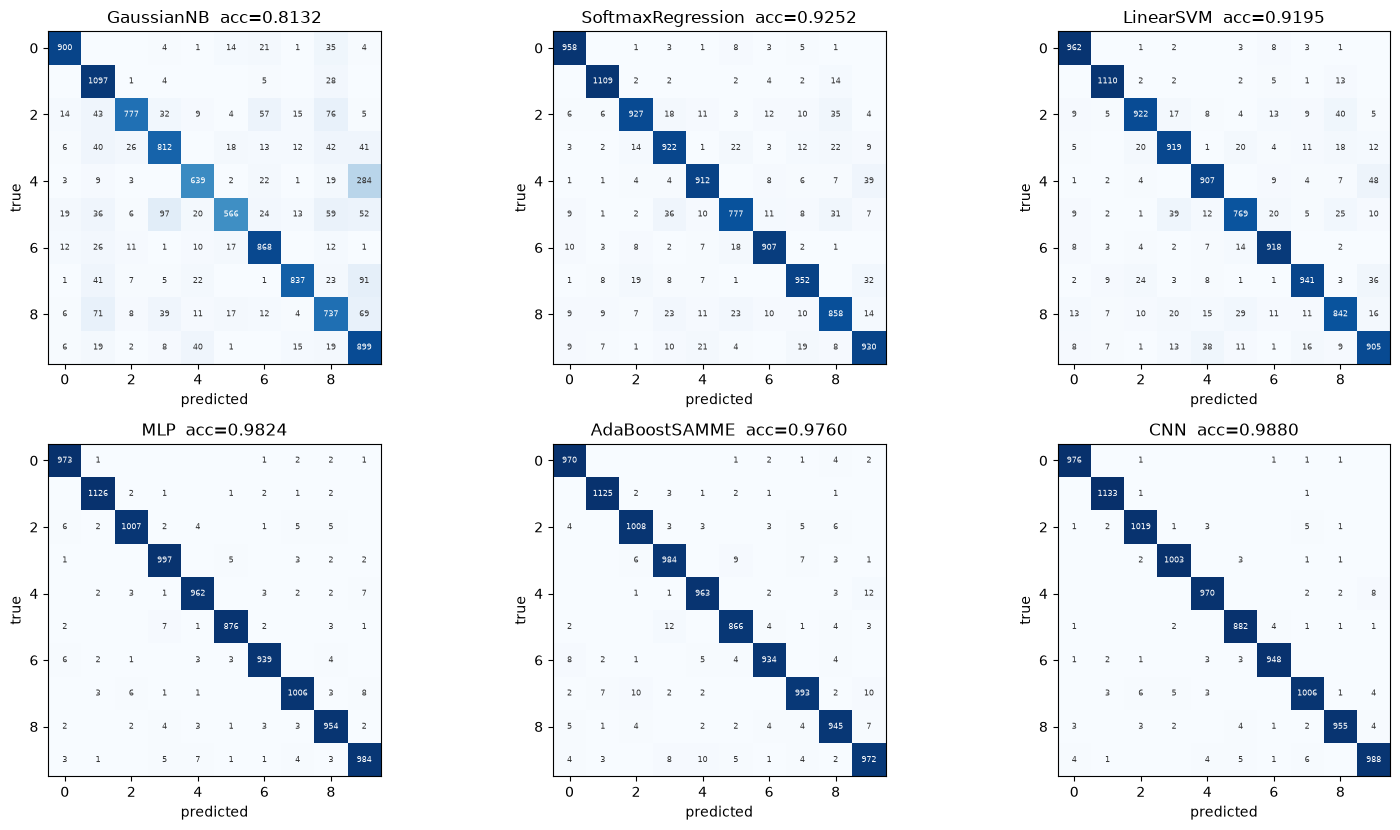

In [6]:
n = len(results)
fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(5.2 * ((n + 1) // 2), 8.4))
for ax, (m, r) in zip(axes.ravel(), results.items()):
    cm = np.array(r["splits"]["test"]["confusion_matrix"])
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                        color="white" if cm[i, j] / cm[i].sum() > .55 else "#333")
    ax.set_title(f"{CLASS_NAME[m]}  acc={r['splits']['test']['accuracy']:.4f}")
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()


## 6. Agreement with the committed run (`results/final`)
Runs are seeded, so accuracies should match exactly on the same machine/library versions; small differences are possible
across hardware/BLAS builds (floating-point summation order).

In [7]:
if QUICK:
    print("QUICK mode: skipped (different training set)")
else:
    cmp = []
    for m, r in results.items():
        ref = json.loads((ROOT / "results" / "final" / f"{CLASS_NAME[m]}.json").read_text())
        cmp.append({"model": CLASS_NAME[m],
                    "test_acc_now": r["splits"]["test"]["accuracy"],
                    "test_acc_committed": ref["splits"]["test"]["accuracy"],
                    "abs_diff": abs(r["splits"]["test"]["accuracy"] - ref["splits"]["test"]["accuracy"])})
    cmp = pd.DataFrame(cmp).set_index("model"); display(cmp.style.format("{:.5f}"))
    assert (cmp["abs_diff"] < 0.002).all(), "results drifted from the committed run"

,test_acc_now,test_acc_committed,abs_diff
model,,,
GaussianNB,0.81320,0.81320,0.00000
SoftmaxRegression,0.92520,0.92520,0.00000
LinearSVM,0.91950,0.91950,0.00000
MLP,0.98240,0.98240,0.00000
AdaBoostSAMME,0.97600,0.97600,0.00000
CNN,0.98800,0.98800,0.00000


## 7. Stacking ensemble

A softmax meta-learner on the log-probabilities (SVM: scores) of the six models, fitted on the **validation** split
(hold-out of the base models); its L2 strength is chosen by 5-fold cross-validation *inside* the validation split.


In [8]:
by_class = {CLASS_NAME[m]: models[m] for m in models}
stack = StackingEnsemble(bases=[(n, by_class[n]) for n in BASE_NAMES])
F_val = stack.features(data["X_val"])
cv = {l2: cv_accuracy(F_val, data["y_val"], l2)[0] for l2 in L2_GRID}
stack.l2 = max(cv, key=cv.get)
stack.fit_features(F_val, data["y_val"])
stack_test = float(np.mean(stack.predict(data["X_test"]) == data["y_test"]))
print("cross-validated accuracy inside validation:", {k: round(v, 4) for k, v in cv.items()})
print(f"selected l2 = {stack.l2}; stacking test accuracy = {stack_test:.4f}; "
      f"best single model = {max(r['splits']['test']['accuracy'] for r in results.values()):.4f}")


cross-validated accuracy inside validation: {0.0001: 0.9869, 0.001: 0.9867, 0.01: 0.9859, 0.1: 0.9833}
selected l2 = 0.0001; stacking test accuracy = 0.9905; best single model = 0.9880


## 8. Plain vs augmented variants

The augmented variant of a model is trained on the original images plus 2 randomly rotated (up to 30 degrees), shifted
and scaled copies, with the same hyper-parameters (recipe: `results/augmentation_deploy_mlp.json`, chosen on the MLP's validation split).
Test images are rotated by a random angle within plus/minus the given range. CNN and AdaBoost variants add about 25 minutes:
extend `AUG_MODELS` to reproduce the full table in `results/augmentation_pairs.json`.


In [9]:
spec = json.loads((ROOT / "results" / "augmentation_deploy_mlp.json").read_text())["spec"]
AUG_MODELS = ["naive_bayes", "softmax", "mlp"]    # + "adaboost", "cnn" for the complete table
aug_models, aug_results = {}, {}
for m in AUG_MODELS:
    aug_models[m], aug_results[m] = train_final(m, best[m], data, meta, tracker=None, save=False,
                                                out_dir=OUT, repeats=1, augment=spec)

def rotated_acc(model, a):
    X = data["X_test"] if a == 0 else transform_images(data["X_test"], ("rotation",), k=1, seed=999, rotation=float(a))
    return float(np.mean(model.predict(X) == data["y_test"]))

rows = []
for m in AUG_MODELS:
    for tag, mod in (("plain", models[m]), ("augmented", aug_models[m])):
        rows.append({"model": CLASS_NAME[m], "variant": tag, **{f"rot{a}": rotated_acc(mod, a) for a in ROTATION_ANGLES}})
pairs = pd.DataFrame(rows).set_index(["model", "variant"])
pairs.style.format("{:.4f}")


[GaussianNB_aug] train=0.6904 val=0.6921 test=0.7064 fit=1.4s


[SoftmaxRegression_aug] train=0.8955 val=0.8850 test=0.8948 fit=31.2s


[MLP_aug] train=0.9923 val=0.9804 test=0.9841 fit=18.4s


## 9. Agreement with the committed run (SVM, stacking, augmented variants)


In [10]:
if QUICK:
    print("QUICK mode: skipped (different training set)")
else:
    stk = json.loads((ROOT / "results" / "final" / "StackingEnsemble.json").read_text())
    pr = json.loads((ROOT / "results" / "augmentation_pairs.json").read_text())["models"]
    chk = [{"item": "stacking test accuracy", "now": stack_test, "committed": stk["splits"]["test"]["accuracy"]}]
    for m in AUG_MODELS:
        chk.append({"item": f"{CLASS_NAME[m]} augmented test accuracy",
                    "now": aug_results[m]["splits"]["test"]["accuracy"], "committed": pr[m]["augmented"]["test_acc"]})
        chk.append({"item": f"{CLASS_NAME[m]} augmented, rotation 30", "now": rotated_acc(aug_models[m], 30),
                    "committed": pr[m]["augmented"]["test_rotation_acc"]["30"]})
    chk = pd.DataFrame(chk).set_index("item"); chk["abs_diff"] = (chk["now"] - chk["committed"]).abs()
    display(chk.style.format("{:.5f}"))
    assert (chk["abs_diff"] < 0.002).all(), "results drifted from the committed run"


,now,committed,abs_diff
item,,,
stacking test accuracy,0.99050,0.99050,0.00000
GaussianNB augmented test accuracy,0.70640,0.70640,0.00000
"GaussianNB augmented, rotation 30",0.61150,0.61150,0.00000
SoftmaxRegression augmented test accuracy,0.89480,0.89480,0.00000
"SoftmaxRegression augmented, rotation 30",0.83830,0.83830,0.00000
MLP augmented test accuracy,0.98410,0.98410,0.00000
"MLP augmented, rotation 30",0.97360,0.97360,0.00000
